# 1. Khảo sát dữ liệu sơ bộ (Initial Exploration)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/raw/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df) * 100).round(2)
missing

,n_missing,pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Cột nào thiếu nhiều nhất?
Với phân tích retention, một dòng không có CustomerID có dùng được không? Vì sao?

Dua vao kqua co the thay co 2 cot chua du lieu bi khuyet thieu (`Description`, `CustomerID`), trong do cot `CustomerID` chiem toi ~25% bi thieu vi vay can loai bo cac dong khuyet thieu khi can phan tich khach hang.

In [3]:
print(df["InvoiceDate"].min(), df["InvoiceDate"].max())

df["Month"] = df["InvoiceDate"].dt.to_period("M")
print(df.groupby("Month")["InvoiceDate"].agg(["min", "max", "count"]).reset_index())

2010-12-01 08:26:00 2011-12-09 12:50:00
      Month                 min                 max  count
0   2010-12 2010-12-01 08:26:00 2010-12-23 17:41:00  42481
1   2011-01 2011-01-04 10:00:00 2011-01-31 16:59:00  35147
2   2011-02 2011-02-01 08:23:00 2011-02-28 17:04:00  27707
3   2011-03 2011-03-01 08:30:00 2011-03-31 19:55:00  36748
4   2011-04 2011-04-01 08:22:00 2011-04-28 19:53:00  29916
5   2011-05 2011-05-01 10:51:00 2011-05-31 15:53:00  37030
6   2011-06 2011-06-01 07:37:00 2011-06-30 20:08:00  36874
7   2011-07 2011-07-01 08:16:00 2011-07-31 16:04:00  39518
8   2011-08 2011-08-01 08:30:00 2011-08-31 17:45:00  35284
9   2011-09 2011-09-01 08:25:00 2011-09-30 17:22:00  50226
10  2011-10 2011-10-02 10:32:00 2011-10-31 17:19:00  60742
11  2011-11 2011-11-01 08:16:00 2011-11-30 17:42:00  84711
12  2011-12 2011-12-01 08:12:00 2011-12-09 12:50:00  25525


Dữ liệu kéo dài bao lâu? Tháng đầu và tháng cuối có đủ ngày không? (Gợi ý: nhìn ngày min và max của từng tháng.)

Du lieu keo dai 1 nam tu 12/2010 - 12/2011 tuy nhien trong thang 12/2011 chi co du lieu cua 9 ngay --> luoc bo 

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64
Khách chỉ mua 1 lần: 30.0 %


<Axes: >

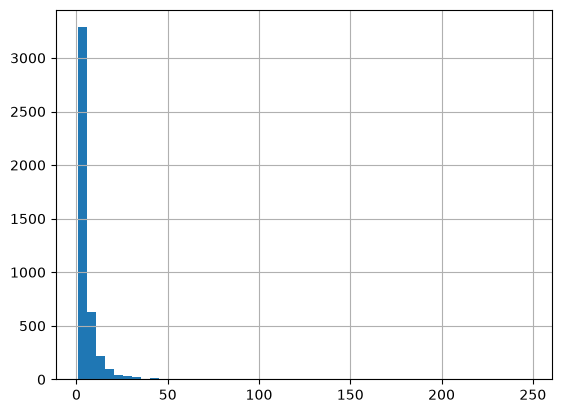

In [4]:
orders = df.groupby("CustomerID")["InvoiceNo"].nunique()
print(orders.describe())
print("Khách chỉ mua 1 lần:", round((orders == 1).mean() * 100, 1), "%")
orders.hist(bins=50)

In [ ]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("Đơn hủy bắt đầu bằng C:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

df[["Quantity", "UnitPrice"]].describe()

Quantity <= 0: 10624
UnitPrice <= 0: 2517
Đơn hủy bắt đầu bằng C: 9288


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


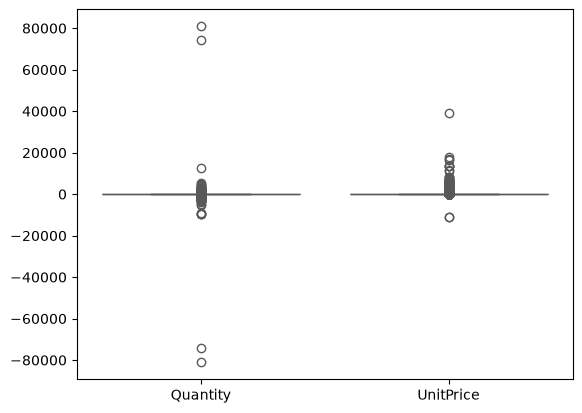

In [7]:
feature = ['Quantity', 'UnitPrice']

ax = sns.boxplot(
    data=df[feature],
    palette="Set2"
)
plt.show()

Q1 và Q3 của cả 2 biến bị nén thành một đường ngang sát mốc 0<br>
`Quantity` < 0 Là các bản ghi trả hàng hoặc hủy đơn hàng (thường mang tiền tố C ở `InvoiceNo`), không phản ánh hành vi mua hàng được giữ chân <br>
`UnitPrice` < 0: Trong khi là đơn giá không thể âm

--> Áp dụng lược bỏ 2 biến `Quantity` > 0 và `UnitPrice` > 0

# Quy trình 4 bước Xử lý & Khám phá Dữ liệu (Exploratory Data Audit)

```
1. KHÁM PHÁ   → chạy code, chỉ nhìn, giữ nguyên df gốc
2. GHI NHẬN   → mỗi phát hiện ghi vào Audit Log
3. QUYẾT ĐỊNH → với mỗi phát hiện: loại / giữ / sửa / ghi chú, và vì sao
4. LÀM SẠCH   → viết code theo đúng các quyết định, đếm số dòng mỗi bước
```

> **Mục tiêu:** Khám phá toàn diện bộ dữ liệu `Online Retail.xlsx` cho bài toán **Customer Retention Analysis** mà không làm biến đổi dữ liệu gốc.

## A. Điều tra các giá trị bất thường (Quantity & UnitPrice)
Khảo sát các trường hợp:
* `Quantity <= 0` nhưng không phải đơn hủy (không có tiền tố `C`)
* Hai dòng cực trị của `Quantity`
* `UnitPrice < 0` và `UnitPrice == 0`

In [9]:
cancel = df["InvoiceNo"].astype(str).str.startswith("C")

display(df[(df["Quantity"] <= 0) | ~cancel].head(10))

display(df.loc[[df["Quantity"].idxmax(), df["Quantity"].idxmin()]])

display(df[df["UnitPrice"] < 0])


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,2010-12
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,2010-12
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,2010-12
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,2010-12
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,2010-12


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,2011-12
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,2011-12


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011-08
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011-08


* **Hai cực trị `Quantity` (±80.995):** Là 2 dòng đối ứng xảy ra sát nhau của cùng 1 khách hàng (`CustomerID: 16446`), mua nhầm và tạo đơn hủy ngay (`581483` và `C581484`)
* **`UnitPrice < 0` (2 dòng):** Là bút toán điều chỉnh nợ xấu (`Adjust bad debt`), không phải giao dịch khách hàng

In [11]:
dup_count = df.duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn: {dup_count:,} ({dup_count / len(df):.2%})")
display(df[df.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(10))

Số dòng trùng lặp hoàn toàn: 5,268 (0.97%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,2010-12
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,2010-12
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,2010-12
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,2010-12
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2010-12
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2010-12
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2010-12
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2010-12
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,2010-12
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,2010-12



* Có **5.268 dòng** trùng khớp 100% tất cả các trường (kể cả thời điểm tới từng giây).
* Trong thương mại điện tử, mua 2 món cùng loại trong 1 đơn sẽ có `Quantity = 2`. Việc xuất hiện 2 dòng giống hệt là lỗi kỹ thuật double-request hoặc đồng bộ hệ thống, cần loại bỏ để tránh đếm trùng doanh thu.

In [ ]:
g = df.dropna(subset=["CustomerID"]).groupby("InvoiceNo")
print("\nSố hóa đơn có nhiều hơn 1 khách hàng:", (g["CustomerID"].nunique() > 1).sum())
print("Số hóa đơn có nhiều hơn 1 thời điểm ghi nhận:", (g["InvoiceDate"].nunique() > 1).sum())

Phân bố số dòng trên mỗi hóa đơn:
count    25900.000000
mean        20.923127
std         43.031334
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1114.000000
dtype: float64

Số hóa đơn có nhiều hơn 1 khách hàng: 0
Số hóa đơn có nhiều hơn 1 thời điểm ghi nhận: 31


* Mỗi hóa đơn chỉ thuộc về duy nhất **1 khách hàng** (`nunique > 1` bằng 0).
* Có 31 hóa đơn xuất hiện nhiều mốc thời gian (lệch vài giây/phút do quá trình quét đơn hàng dài). Khi phân tích Cohort, ta sẽ lấy `min(InvoiceDate)` của mỗi hóa đơn.

In [14]:
c = df[cancel]
display(c.head(10))
print(f"Tổng số dòng đơn hủy: {len(c)}")
print(f"Tỷ lệ đơn hủy thiếu CustomerID: {c['CustomerID'].isna().mean():.2%}")
print(f"Tỷ lệ đơn hủy có Quantity < 0: {c['Quantity'].lt(0).mean():.2%}")
print(f"Doanh thu âm từ đơn hủy: {(c['Quantity'] * c['UnitPrice']).sum():,.2f}")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,2010-12
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,2010-12
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,2010-12
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,2010-12
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,2010-12
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,2010-12
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom,2010-12
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,2010-12
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,2010-12
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom,2010-12


Tổng số dòng đơn hủy: 9288
Tỷ lệ đơn hủy thiếu CustomerID: 4.12%
Tỷ lệ đơn hủy có Quantity < 0: 100.00%
Doanh thu âm từ đơn hủy: -896,812.49


* 100% đơn hủy có `Quantity < 0`.
* 95,88% đơn hủy có gắn `CustomerID` cụ thể (chỉ 4,12% bị null).
* Không thể ghép trực tiếp đơn hủy vào đơn gốc chỉ bằng cách bỏ tiền tố `C` (vì mã hóa đơn tăng dần tuần tự). Ngoài ra có hiện tượng đơn hủy đối với các đơn hàng mua trước tháng 12/2010 (không có đơn mua gốc trong tập dữ liệu).

In [15]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")

print(f"Tỷ lệ thiếu CustomerID toàn bộ: {df['CustomerID'].isna().mean():.2%}")

print("\nTỷ lệ thiếu theo tháng:")
print(df.groupby("Month")["CustomerID"].apply(lambda s: s.isna().mean()))

print("\nTop 10 quốc gia có tỷ lệ thiếu CustomerID cao nhất:")
print(df.groupby("Country")["CustomerID"].apply(lambda s: s.isna().mean()).sort_values().tail(10))

print("\nKiểm tra hóa đơn thiếu CustomerID (0.0: đầy đủ, 1.0: thiếu cả hóa đơn):")
print(df.groupby("InvoiceNo")["CustomerID"].apply(lambda s: s.isna().mean()).value_counts())

Tỷ lệ thiếu CustomerID toàn bộ: 24.93%

Tỷ lệ thiếu theo tháng:
Month
2010-12    0.367953
2011-01    0.376561
2011-02    0.265059
2011-03    0.242898
2011-04    0.224562
2011-05    0.219336
2011-06    0.245105
2011-07    0.304064
2011-08    0.216019
2011-09    0.187234
2011-10    0.165404
2011-11    0.225626
2011-12    0.308090
Freq: M, Name: CustomerID, dtype: float64

Top 10 quốc gia có tỷ lệ thiếu CustomerID cao nhất:
Country
United Arab Emirates    0.000000
France                  0.007713
Portugal                0.025675
Switzerland             0.062438
EIRE                    0.086750
Bahrain                 0.105263
Israel                  0.158249
United Kingdom          0.269639
Unspecified             0.452915
Hong Kong               1.000000
Name: CustomerID, dtype: float64

Kiểm tra hóa đơn thiếu CustomerID (0.0: đầy đủ, 1.0: thiếu cả hóa đơn):
CustomerID
0.0    22190
1.0     3710
Name: count, dtype: int64


* Thiếu cả hóa đơn: Một hóa đơn hoặc có đủ 100% `CustomerID`, hoặc thiếu 100% (toàn bộ 3.710 hóa đơn thiếu là do khách mua vãng lai - Guest Checkout).
* Tập trung địa lý: **98,9% số dòng thiếu CustomerID nằm tại UK**. Trong khi đó các đơn quốc tế hầu hết đều yêu cầu đăng ký tài khoản.

In [17]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
monthly = df.groupby("Month").agg(
    rows=("InvoiceNo", "size"),
    invoices=("InvoiceNo", "nunique"),
    revenue=("Revenue", "sum")
)
display(monthly)
print(f"Tổng số ngày giao dịch: {df['InvoiceDate'].dt.date.nunique()}")
print(f"Khoảng thời gian: {df['InvoiceDate'].min()} -> {df['InvoiceDate'].max()}")

,rows,invoices,revenue
Month,,,
2010-12,42481,2025,748957.020
2011-01,35147,1476,560000.260
2011-02,27707,1393,498062.650
2011-03,36748,1983,683267.080
2011-04,29916,1744,493207.121
2011-05,37030,2162,723333.510
2011-06,36874,2012,691123.120
2011-07,39518,1927,681300.111
2011-08,35284,1737,682680.510


Tổng số ngày giao dịch: 305
Khoảng thời gian: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


* Dữ liệu dừng lại ở ngày **09/12/2011**, khiến tháng 12/2011 chỉ có 9 ngày ghi nhận. Nếu đưa tháng 12/2011 vào phân tích Cohort theo tháng sẽ làm tỷ lệ Retention bị sụt giảm giả tạo.

In [18]:
print("Top 10 quốc gia có số dòng nhiều nhất:")
print(df["Country"].value_counts().head(10))

# Phân tích tập trung doanh thu trên tập có CustomerID
df_cust = df.dropna(subset=["CustomerID"])
cust_rev = df_cust.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
top_20_count = int(len(cust_rev) * 0.2)
top_20_rev_share = cust_rev.iloc[:top_20_count].sum() / cust_rev.sum()

print(f"\nTổng số khách hàng có ID: {len(cust_rev):,}")
print(f"Top 20% khách hàng ({top_20_count:,} người) đóng góp: {top_20_rev_share:.2%} tổng doanh thu")

Top 10 quốc gia có số dòng nhiều nhất:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Tổng số khách hàng có ID: 4,372
Top 20% khách hàng (874 người) đóng góp: 73.82% tổng doanh thu
